# Hate Speech Detection Using NLP and Machine Learning

## Overview
This project explores text classification for identifying hate speech and offensive language in tweets using Natural Language Processing (NLP) techniques and a Decision Tree classifier.

## Objectives
- Inspect and understand the labelled tweet dataset.
- Preprocess text through cleaning, stopword removal, and stemming.
- Convert text into numerical features using CountVectorizer.
- Train a Decision Tree classifier to classify tweets into three categories.
- Evaluate model performance using a confusion matrix and accuracy.
- Test the trained model on a sample tweet.

## Tools & Libraries
Python, Pandas, NumPy, NLTK, Scikit-learn, Matplotlib, Seaborn.

## Dataset

**Dataset Source:** [Hate Speech and Offensive Language Dataset – Kaggle](https://www.kaggle.com/datasets/mrmorj/hate-speech-and-offensive-language-dataset)

**File Used:** `labeled_data.csv`

**Records:** 24,783 tweets

**Original Columns:** 7

**Target Variable:** `class`
- `0` — Hate speech
- `1` — Offensive language
- `2` — Neither

**Description:** The dataset contains tweets labelled according to whether they contain hate speech, offensive language, or neither.

**Setup:** Download `labeled_data.csv` from the Kaggle source linked above and place it in the same directory as this notebook before running the analysis.

In [1]:
import pandas as pd 
import numpy as np

In [3]:
dataset=pd.read_csv("C:/College/Datasets/archive (6)/labeled_data.csv")

In [4]:
dataset

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...
...,...,...,...,...,...,...,...
24778,25291,3,0,2,1,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...
24779,25292,3,0,1,2,2,"you've gone and broke the wrong heart baby, an..."
24780,25294,3,0,3,0,1,young buck wanna eat!!.. dat nigguh like I ain...
24781,25295,6,0,6,0,1,youu got wild bitches tellin you lies


In [5]:
dataset.isnull().sum()

Unnamed: 0            0
count                 0
hate_speech           0
offensive_language    0
neither               0
class                 0
tweet                 0
dtype: int64

In [6]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Unnamed: 0          24783 non-null  int64 
 1   count               24783 non-null  int64 
 2   hate_speech         24783 non-null  int64 
 3   offensive_language  24783 non-null  int64 
 4   neither             24783 non-null  int64 
 5   class               24783 non-null  int64 
 6   tweet               24783 non-null  object
dtypes: int64(6), object(1)
memory usage: 1.3+ MB


In [7]:
dataset.describe()

,Unnamed: 0,count,hate_speech,offensive_language,neither,class
count,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000,24783.000000
mean,12681.192027,3.243473,0.280515,2.413711,0.549247,1.110277
std,7299.553863,0.883060,0.631851,1.399459,1.113299,0.462089
min,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000
25%,6372.500000,3.000000,0.000000,2.000000,0.000000,1.000000
50%,12703.000000,3.000000,0.000000,3.000000,0.000000,1.000000
75%,18995.500000,3.000000,0.000000,3.000000,0.000000,1.000000
max,25296.000000,9.000000,7.000000,9.000000,9.000000,2.000000


### Target Class Labels

The `class` column contains three categories:

| Label | Category |
|---|---|
| 0 | Hate speech |
| 1 | Offensive language |
| 2 | Neither |

These numerical labels represent the three classes the model is trained to predict.

In [8]:
dataset["label"]=dataset["class"].map({0:"hate speech",1:"offensive language",2:"no hate or offensive language"})

In [9]:
dataset

,Unnamed: 0,count,hate_speech,offensive_language,neither,class,tweet,label
0,0,3,0,0,3,2,!!! RT @mayasolovely: As a woman you shouldn't...,no hate or offensive language
1,1,3,0,3,0,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,offensive language
2,2,3,0,3,0,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,offensive language
3,3,3,0,2,1,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,offensive language
4,4,6,0,6,0,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,offensive language
...,...,...,...,...,...,...,...,...
24778,25291,3,0,2,1,1,you's a muthaf***in lie &#8220;@LifeAsKing: @2...,offensive language
24779,25292,3,0,1,2,2,"you've gone and broke the wrong heart baby, an...",no hate or offensive language
24780,25294,3,0,3,0,1,young buck wanna eat!!.. dat nigguh like I ain...,offensive language
24781,25295,6,0,6,0,1,youu got wild bitches tellin you lies,offensive language


In [10]:
data=dataset[["tweet","label"]]

In [11]:
data

,tweet,label
0,!!! RT @mayasolovely: As a woman you shouldn't...,no hate or offensive language
1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,offensive language
2,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,offensive language
3,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,offensive language
4,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,offensive language
...,...,...
24778,you's a muthaf***in lie &#8220;@LifeAsKing: @2...,offensive language
24779,"you've gone and broke the wrong heart baby, an...",no hate or offensive language
24780,young buck wanna eat!!.. dat nigguh like I ain...,offensive language
24781,youu got wild bitches tellin you lies,offensive language


In [15]:
import re
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [ ]:
#importing stop words 
from nltk.corpus import stopwords
stopwords=set(stopwords.words("english"))

In [18]:
stopwords

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

### Stopword Removal

Stopwords are commonly occurring words that often carry limited task-specific information, such as *a*, *an*, *the*, *is*, and *if*.

Removing stopwords can reduce the number of features in a text dataset and simplify text processing. However, the decision to remove them depends on the task, since some common words may carry important meaning in certain contexts.

In [17]:
#import Stemming
stemmer=nltk.SnowballStemmer("english")

### Stemming

Stemming is a text-preprocessing technique that reduces words to their root or stem by removing prefixes or suffixes.

For example, *cleaning*, *cleaned*, and *cleaner* may all be reduced to the stem *clean*.

The resulting stem may not always be a valid dictionary word, but stemming helps reduce variations of related words.

### Lemmatization

Lemmatization reduces a word to its dictionary base form (lemma), taking its meaning and grammatical context into account.

For example:
- *am*, *are*, *is* → *be*
- *better*, *best* → *good*
- *running* → *run*

Unlike stemming, lemmatization aims to produce valid dictionary words.

In [23]:
from string import punctuation

In [29]:
#data cleaning
def clean_data(text):
    text=str(text).lower()
    text = re.sub("https?://\S+|www\.S+","",text) #\S is escape notation
    text = re.sub("\[.*?\]","",text)
    text = re.sub("<.*?>+","",text)
    text = re.sub('[%s]' %re.escape(string.punctuation),"",text)
    text = re.sub('\n',"",text)
    text = re.sub('\w*\d\w*',"",text)
#these are basic escape characters in any HTML based doc
#stopword removal
    text = [word for word in text.split(' ') if word not in stopwords]
#we have looped through the words in text after splitting them using individual tokenizing
#we can also tokenize it first, then use it
    text = " ".join(text) 
#stemming the text
    text = [stemmer.stem(word) for word in text.split(" ")]
    text = " ".join(text)
    return text

<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\['
<>:9: SyntaxWarning: invalid escape sequence '\w'
<>:4: SyntaxWarning: invalid escape sequence '\S'
<>:5: SyntaxWarning: invalid escape sequence '\['
<>:9: SyntaxWarning: invalid escape sequence '\w'
C:\Users\Admin\AppData\Local\Temp\ipykernel_1772\2855162067.py:4: SyntaxWarning: invalid escape sequence '\S'
  text = re.sub("https?://\S+|www\.S+","",text) #\S is escape notation
C:\Users\Admin\AppData\Local\Temp\ipykernel_1772\2855162067.py:5: SyntaxWarning: invalid escape sequence '\['
  text = re.sub("\[.*?\]","",text)
C:\Users\Admin\AppData\Local\Temp\ipykernel_1772\2855162067.py:9: SyntaxWarning: invalid escape sequence '\w'
  text = re.sub('\w*\d\w*',"",text)


In [27]:
import string

In [30]:
data["tweet"] = data["tweet"].apply(clean_data)

C:\Users\Admin\AppData\Local\Temp\ipykernel_1772\1832165696.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["tweet"] = data["tweet"].apply(clean_data)


### Note on Views and Copies in Pandas

In Pandas, some operations may return a view of the original DataFrame, while others return an independent copy.

- **View:** Changes may affect the original data.
- **Copy:** Changes are made to a separate object and do not affect the original data.

The behaviour depends on the operation. Refer to the Pandas documentation when deciding whether an explicit copy is needed.

In [31]:
data

,tweet,label
0,rt mayasolov woman shouldnt complain clean ho...,no hate or offensive language
1,rt boy dat coldtyga dwn bad cuffin dat hoe ...,offensive language
2,rt urkindofbrand dawg rt ever fuck bitch sta...,offensive language
3,rt cganderson vivabas look like tranni,offensive language
4,rt shenikarobert shit hear might true might f...,offensive language
...,...,...
24778,yous muthafin lie coreyemanuel right tl tras...,offensive language
24779,youv gone broke wrong heart babi drove redneck...,no hate or offensive language
24780,young buck wanna eat dat nigguh like aint fuck...,offensive language
24781,youu got wild bitch tellin lie,offensive language


### Alternative Text-Cleaning Approach

Instead of removing unwanted words or characters, we can also retain only the words or patterns that are useful for the task.

For example, regular expressions can help extract only alphabetic words from text. The choice of cleaning approach depends on the dataset and the information we want to preserve.

In [32]:
x = np.array(data["tweet"])
y = np.array(data["label"])

### Text Vectorization

Machine learning algorithms cannot directly process raw text. We therefore convert the preprocessed tweets into numerical representations.

Here, we use `CountVectorizer` to implement the Bag-of-Words approach. It builds a vocabulary from the training text and represents each document using word-frequency counts.

In [33]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

In [34]:
cv = CountVectorizer() #object is created
X = cv.fit_transform(x)

In [35]:
X

<24783x25693 sparse matrix of type '<class 'numpy.int64'>'
	with 197861 stored elements in Compressed Sparse Row format>

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)
#random state is a number you can give for controlling the randomizing of states
#basically, first data won't go as first, it will get jumbled up

In [37]:
X_train

<16604x25693 sparse matrix of type '<class 'numpy.int64'>'
	with 132619 stored elements in Compressed Sparse Row format>

In [38]:
#building our ML model
from sklearn.tree import DecisionTreeClassifier

In [39]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

DecisionTreeClassifier()

In [40]:
y_pred = dt.predict(X_test)

### Making Predictions on the Test Set

We pass `X_test` to the trained model to obtain predictions (`y_pred`).

We do not pass `y_test` to `predict()`, because it contains the actual labels. Instead, we compare `y_pred` with `y_test` to evaluate how accurately the model classifies unseen data.

In [42]:
#confusion matrix and accuracy
from sklearn.metrics import confusion_matrix
cn =  confusion_matrix(y_test, y_pred)
cn

array([[ 156,   35,  274],
       [  36, 1122,  221],
       [ 244,  225, 5866]], dtype=int64)

### Model Performance Observations

The confusion matrix shows that the model does not perform equally well across all three classes.

In particular, the model has difficulty identifying hate speech correctly, with a considerable number of hate speech samples being misclassified.

The overall accuracy is approximately 87.35%. However, accuracy alone does not reveal how well the model performs on each class.

Further evaluation using class-wise precision, recall, and F1-score would provide a more complete picture of model performance.

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt
#%matplotlib inline

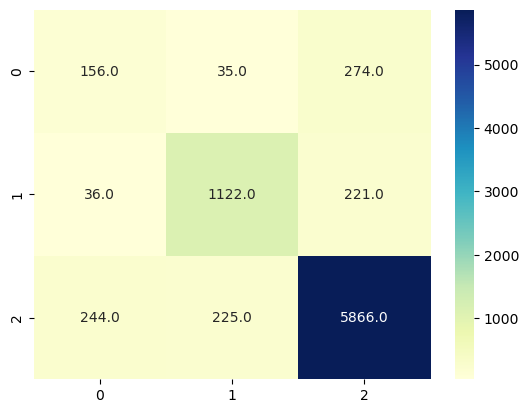

In [48]:
sns.heatmap(cn, annot=True, fmt=".1f", cmap="YlGnBu")
plt.show()

### Note on Inline Plotting

`%matplotlib inline` enables Matplotlib figures to be displayed directly within a Jupyter Notebook.

It controls how figures are rendered, not how they are styled. If a plot looks cluttered, its appearance may need to be improved by adjusting the figure size, labels, or layout.

### Interpreting the Confusion Matrix

In a confusion matrix, the diagonal elements represent correctly classified observations, while the off-diagonal elements represent misclassifications.

A darker diagonal compared with the off-diagonal cells generally indicates better classification performance. However, the values should also be considered in relation to the number of samples in each class.

### Possible Reason for Poor Class Performance

The model's weaker performance on the first class (hate speech) may be related to the number of training examples available for that class.

However, this is only a possible explanation. We would need to examine the class distribution and per-class evaluation metrics to determine whether class imbalance is contributing to the problem.

### Possible Improvement: Handling Class Imbalance

If the training dataset has an unequal distribution of classes, oversampling the underrepresented class could be explored.

One approach is to duplicate selected samples from the minority class in the training set. This may help the model learn from that class more effectively.

However, oversampling should be applied only to the training data, not the test data. Its effectiveness should be evaluated using per-class precision, recall, and F1-score.

In [49]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.8734564127643967

In [50]:
sample = "Let's unite and kill all the people who are protesting against the government"
sample = clean_data(sample)
sample

'let unit kill peopl protest govern'

In [51]:
data1 = cv.transform([sample]).toarray()

In [52]:
data1

array([[0, 0, 0, ..., 0, 0, 0]], dtype=int64)

In [53]:
dt.predict(data1)

array(['hate speech'], dtype=object)

## Conclusion

This project explored a Natural Language Processing approach to classifying tweets into three categories: hate speech, offensive language, and neither.

The workflow involved text cleaning, stopword removal, stemming, Bag-of-Words feature extraction using `CountVectorizer`, and classification using a Decision Tree model.

The model achieved an accuracy of approximately **87.35%** on the test set. It also successfully classified the sample tweet as hate speech.

Although the model provides a useful starting point, its performance can be further investigated through class-wise evaluation and experiments with other feature extraction and classification techniques.